In [61]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import (precision_score, recall_score, f1_score)
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

In [62]:
np.random.seed(42)
n_customers = 5000

In [63]:
df = pd.DataFrame({
    "customer_id":[
        f"CUST_{i:05d}"
        for i in range(1,n_customers + 1)
    ],
    "age":np.random.randint(
        18,75,n_customers
        ),
    "gender":np.random.choice(
        ["male","female"],
        n_customers
    )
})

In [64]:
df["tenure_months"] = np.random.randint(
    1,
    73,
    n_customers
)
df["contract_type"] = np.random.choice(
    [
        "month-to-month",
        "one year",
        "two year"
    ],size = n_customers,
    p = [0.55,0.25,0.20]
)
df["payment_method"] = np.random.choice(
    [
        "credit card",
        "bank transfer",
        "electronic check",
        "mailed check"
    ],size = n_customers,
    p = [0.30,0.35,0.25,0.10]
)

In [65]:
df["num_devices"] = np.random.choice(
    [1,2,3,4,5],
    size = n_customers,
    p = [0.20,0.35,0.25,0.15,0.05]
)
df["internet_services"] = np.random.choice(
    ["Fibre","DSL","None"],
    size = n_customers,
    p = [0.50,0.35,0.15]
)
df["streaming"] = np.random.choice(
    [1,0],
    size = n_customers,
    p = [0.60,0.40]
)
base_plan = 35
internet_cost = np.where(
    df["internet_services"] == "Fibre",
    25,
    np.where(
        df["internet_services"] == "DSL",
        15,
        0
    )
)
streaming_cost = np.where(
    df["streaming"] == 1,
    10,
    0
)
device_cost = df["num_devices"] * 8
noise = np.random.normal(0,5,n_customers)
df["monthly_charges"] = base_plan + internet_cost + streaming_cost + device_cost + noise
df["monthly_charges"] = df["monthly_charges"].clip(35,150)
variation = np.random.normal(1,0.05,n_customers)
df["total_charges"] = (
    df["monthly_charges"] * df["tenure_months"] * variation
    ).round(2)
df["monthly_charges"].describe()

,monthly_charges
count,5000.000000
mean,79.210608
std,14.369613
min,35.000000
25%,69.686797
50%,79.661513
75%,88.947290
max,120.271009


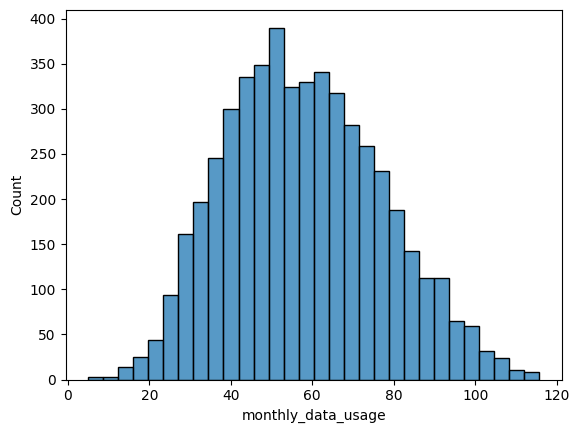

In [66]:
base_usage = np.random.normal(20, 5, n_customers)
usage_noise = np.random.normal(0, 8, n_customers)
df["monthly_data_usage"] = (
    base_usage +
    df["num_devices"] * 15 +
    usage_noise
).clip(lower = 5).round(1)
sns.histplot(df['monthly_data_usage'], bins = 30)
plt.show()

In [67]:
df["support_tickets"] = np.random.poisson(
    lam = 2,
    size = n_customers
)
df["support_tickets"].value_counts().sort_index()

,count
support_tickets,
0,657
1,1369
2,1347
3,924
4,432
5,176
6,69
7,21
8,2


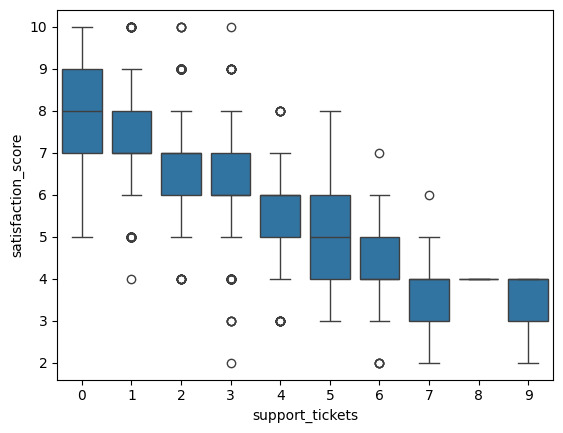

In [68]:
satisfaction_noise = np.random.normal(0, 1, n_customers)
df["satisfaction_score"] = (
    8 -
    df["support_tickets"] * 0.6 +
    satisfaction_noise
).clip(1, 10).round()
sns.boxplot(
    x = df['support_tickets'],
    y = df['satisfaction_score']
)
plt.show()

In [69]:
churn_score = np.zeros(n_customers)
churn_score += np.where(
    df["contract_type"] == "month-to-month",
    1.5,
    0
)
churn_score += np.where(
    df["tenure_months"] < 12,
    1.2,
    0
)
churn_score += np.where(
    df["monthly_charges"] > 80,
    0.8,
    0
)
churn_score += df["support_tickets"] * 0.25
churn_score += (5 - df["satisfaction_score"]) * 0.3
df["churn_score"] = churn_score
df["churn_score"].describe()

,churn_score
count,5000.000000
mean,1.353090
std,1.192591
min,-1.500000
25%,0.450000
50%,1.350000
75%,2.200000
max,5.900000


In [70]:
churn_probability = 1 / (
    1 + np.exp(-(churn_score - 2.5))
)
df["churn_probability"] = churn_probability
df["churn"] = np.random.binomial(
    1,
    df["churn_probability"]
)
df["churn"].value_counts(normalize = True)

,proportion
churn,
0,0.7096
1,0.2904


In [71]:
df.groupby("churn")["churn_probability"].mean()

,churn_probability
churn,
0,0.230056
1,0.433084


In [72]:
df.describe()

,age,tenure_months,num_devices,streaming,monthly_charges,total_charges,monthly_data_usage,support_tickets,satisfaction_score,churn_score,churn_probability,churn
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000
mean,46.148600,36.616600,2.534600,0.598600,79.210608,2902.568240,58.05594,2.00940,6.817800,1.353090,0.289015,0.290400
std,16.325753,20.938101,1.120649,0.490231,14.369613,1778.654225,19.15534,1.42004,1.328968,1.192591,0.206937,0.453992
min,18.000000,1.000000,1.000000,0.000000,35.000000,36.800000,5.00000,0.00000,2.000000,-1.500000,0.017986,0.000000
25%,32.000000,18.000000,2.000000,0.000000,69.686797,1416.255000,43.60000,1.00000,6.000000,0.450000,0.114052,0.000000
50%,46.000000,37.000000,2.000000,1.000000,79.661513,2774.195000,56.80000,2.00000,7.000000,1.350000,0.240489,0.000000
75%,60.000000,55.000000,3.000000,1.000000,88.947290,4272.085000,71.40000,3.00000,8.000000,2.200000,0.425557,1.000000
max,74.000000,72.000000,5.000000,1.000000,120.271009,8484.990000,115.70000,9.00000,10.000000,5.900000,0.967705,1.000000


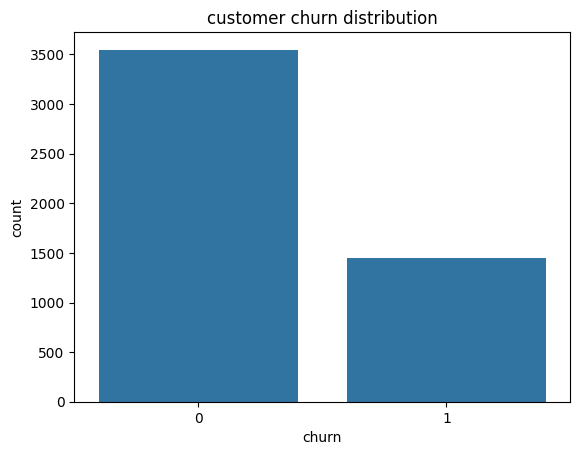

In [73]:
sns.countplot(x = "churn", data = df)
plt.title("customer churn distribution")
plt.xlabel = "churn"
plt.ylabel = "number of customer"
plt.show()

In [74]:
pd.crosstab(
    df["contract_type"],
    df["churn"],
    normalize = "index"
).mul(100).round(2)

churn,0,1
contract_type,,
month-to-month,59.92,40.08
one year,84.51,15.49
two year,84.44,15.56


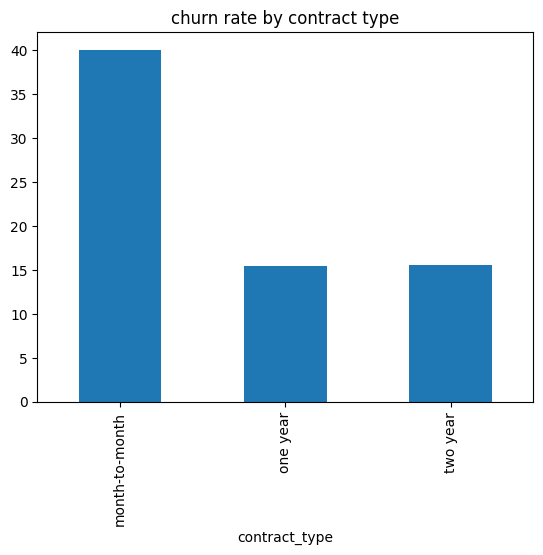

In [75]:
contract_churn = (
    df.groupby("contract_type")["churn"]
    .mean()
    .mul(100)
    .round(2)
)
contract_churn.plot(kind = "bar")
plt.title("churn rate by contract type")
plt.xlabel = "contract type"
plt.ylabel = "churn rate(%)"
plt.show()

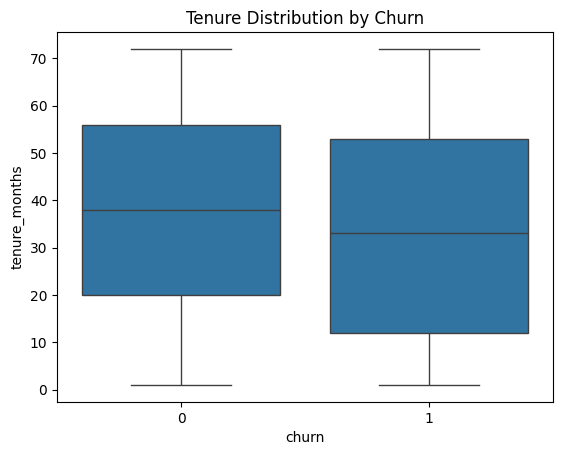

In [76]:
df.groupby("churn")["tenure_months"].mean()
sns.boxplot(
    x="churn",
    y="tenure_months",
    data=df
)
plt.title("Tenure Distribution by Churn")
plt.xlabel = "churn"
plt.ylabel = "tenure (Months)"
plt.show()

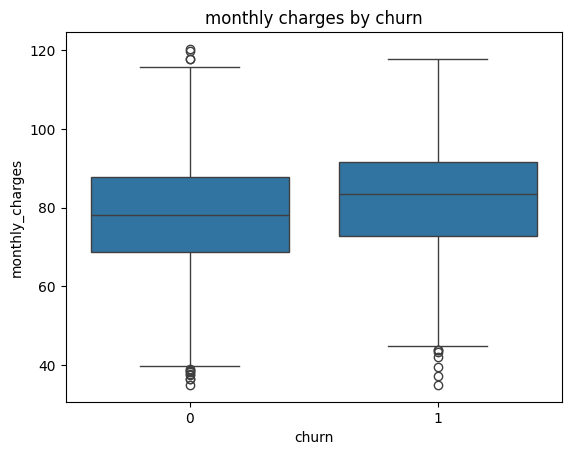

In [77]:
df.groupby("churn")["monthly_charges"].mean()
sns.boxplot(
    x = "churn",
    y = "monthly_charges",
    data = df
)
plt.title("monthly charges by churn")
plt.xlabel = "churn"
plt.ylabel = "monthly charges"
plt.show()

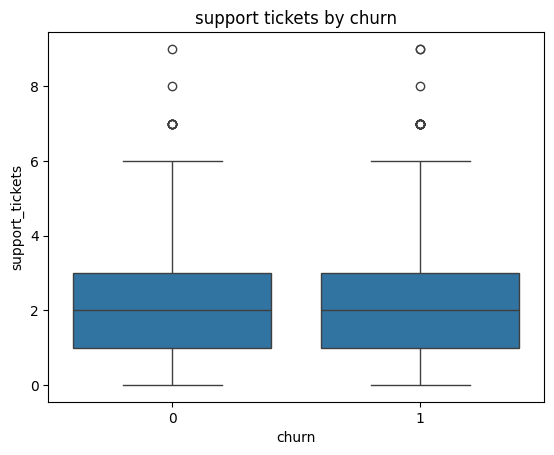

In [78]:
df.groupby("churn")["support_tickets"].mean()
sns.boxplot(
    x = "churn",
    y = "support_tickets",
    data = df
)
plt.title("support tickets by churn")
plt.xlabel = "churn"
plt.ylabel = "support tickets"
plt.show()

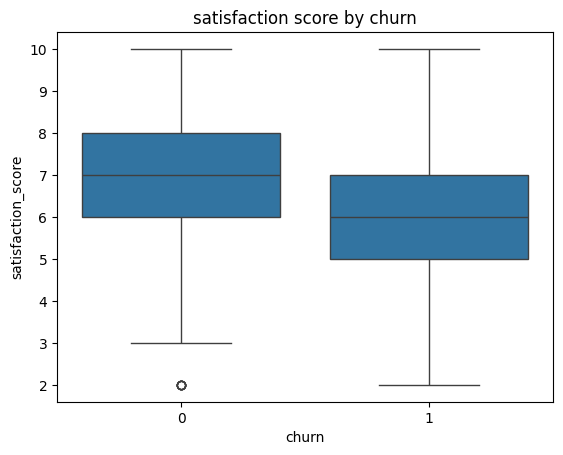

In [79]:
df.groupby("churn")["satisfaction_score"].mean()
sns.boxplot(
    x = "churn",
    y = "satisfaction_score",
    data = df
)
plt.title("satisfaction score by churn")
plt.xlabel = "churn"
plt.ylabel = "satisfaction score"
plt.show()

In [80]:
df.groupby("payment_method")["churn"].mean().mul(100).round(2)

,churn
payment_method,
bank transfer,29.42
credit card,29.85
electronic check,27.21
mailed check,30.10


In [81]:
df.groupby("internet_services")["churn"].mean().mul(100).round(2)

,churn
internet_services,
DSL,26.07
Fibre,32.60
None,23.56


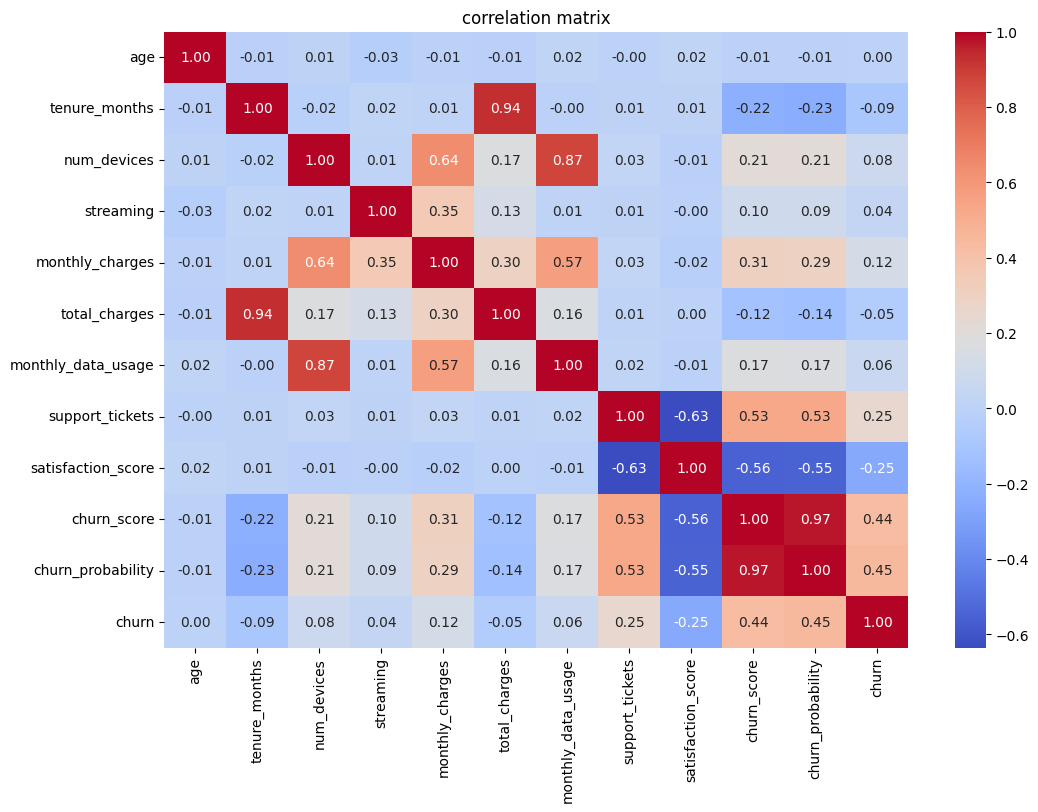

In [82]:
plt.figure(figsize = (12,8))
sns.heatmap(
    df.corr(numeric_only = True),
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)
plt.title("correlation matrix")
plt.show()

In [83]:
eda_summary = df.groupby("churn").agg({
    "tenure_months": "mean",
    "monthly_charges": "mean",
    "support_tickets": "mean",
    "satisfaction_score": "mean",
    "num_devices": "mean",
    "monthly_data_usage": "mean"
}).round(2)
eda_summary

,tenure_months,monthly_charges,support_tickets,satisfaction_score,num_devices,monthly_data_usage
churn,,,,,,
0,37.88,78.09,1.78,7.03,2.48,57.28
1,33.54,81.95,2.57,6.29,2.67,59.95


In [84]:
numeric_features = df[
    [
        "age",
        "tenure_months",
        "num_devices",
        "streaming",
        "monthly_charges",
        "total_charges",
        "monthly_data_usage",
        "support_tickets",
        "satisfaction_score"
    ]
]
vif = pd.DataFrame()
vif["features"] = numeric_features.columns
vif["VIF"] = [
    variance_inflation_factor(
        numeric_features.values,
        i
    )
    for i in range (numeric_features.shape[1])
]
vif

,features,VIF
0,age,1.002249
1,tenure_months,23.987857
2,num_devices,5.089493
3,streaming,1.253496
4,monthly_charges,4.372325
5,total_charges,26.420084
6,monthly_data_usage,4.260540
7,support_tickets,1.678404
8,satisfaction_score,1.677421


In [85]:
features = [
    "age",
    "tenure_months",
    "gender",
    "contract_type",
    "payment_method",
    "num_devices",
    "internet_services",
    "streaming",
    "monthly_charges",
    "monthly_data_usage",
    "support_tickets",
    "satisfaction_score"
]

X = df[features]
y = df["churn"]
X.head()

,age,tenure_months,gender,contract_type,payment_method,num_devices,internet_services,streaming,monthly_charges,monthly_data_usage,support_tickets,satisfaction_score
0,56,28,male,month-to-month,bank transfer,1,DSL,1,59.343420,36.0,2,6.0
1,69,5,male,month-to-month,bank transfer,5,Fibre,1,103.213581,108.8,2,7.0
2,46,21,female,one year,electronic check,3,Fibre,0,88.970840,61.5,1,8.0
3,32,18,female,month-to-month,electronic check,2,DSL,0,61.152213,59.7,3,5.0
4,60,47,male,month-to-month,credit card,2,DSL,1,77.989222,52.1,3,5.0


In [86]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print("training churn rate:", y_train.mean())
print("testing churn rate:", y_test.mean())

(4000, 12)
(1000, 12)
(4000,)
(1000,)
training churn rate: 0.2905
testing churn rate: 0.29


In [87]:
numeric_features_new = [
    "age",
    "tenure_months",
    "num_devices",
    "streaming",
    "monthly_charges",
    "monthly_data_usage",
    "support_tickets",
    "satisfaction_score"
]
categorical_features = [
    "gender",
    "contract_type",
    "payment_method",
    "internet_services"
]

In [88]:
encoder = OneHotEncoder(
    handle_unknown = "ignore",
    sparse_output = False
)
X_train_encoded = encoder.fit_transform(
    X_train[categorical_features]
)
X_test_encoded = encoder.transform(
    X_test[categorical_features]
)
print(X_train_encoded.shape)
print(X_test_encoded.shape)
print(encoder.get_feature_names_out(categorical_features))

(4000, 12)
(1000, 12)
['gender_female' 'gender_male' 'contract_type_month-to-month'
 'contract_type_one year' 'contract_type_two year'
 'payment_method_bank transfer' 'payment_method_credit card'
 'payment_method_electronic check' 'payment_method_mailed check'
 'internet_services_DSL' 'internet_services_Fibre'
 'internet_services_None']


In [89]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(
    X_train[numeric_features_new]
)
X_test_scaled = scaler.transform(
    X_test[numeric_features_new]
)
print(X_train_scaled.shape)
print(X_test_scaled.shape)
print(X_train_scaled.mean(axis = 0))
print(X_test_scaled.std(axis = 0))
print("\n")
print(X_test_scaled.mean(axis = 0))

(4000, 8)
(1000, 8)
[ 1.84741111e-16  1.27009514e-16  1.55431223e-17 -1.00808251e-16
 -3.73923115e-16  6.83897383e-17 -1.59872116e-17  3.28626015e-17]
[0.99507083 1.02023454 0.99618766 0.99333391 0.96396078 1.00131517
 1.03994309 1.00487634]


[ 0.09035786  0.04487324 -0.02407837  0.03158141 -0.05608843  0.00221037
  0.09022663 -0.06197579]


In [90]:
print("Scaler means:")
print(scaler.mean_)

print("\nScaled training means:")
print(X_train_scaled.mean(axis=0))

print("\nScaled training std:")
print(X_train_scaled.std(axis=0))

Scaler means:
[45.8535     36.4295      2.54        0.5955     79.37289754 58.047475
  1.984       6.83425   ]

Scaled training means:
[ 1.84741111e-16  1.27009514e-16  1.55431223e-17 -1.00808251e-16
 -3.73923115e-16  6.83897383e-17 -1.59872116e-17  3.28626015e-17]

Scaled training std:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [91]:
preprocessor = ColumnTransformer(
    [
        (
            "num",
            StandardScaler(),
            numeric_features_new
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown = "ignore",
                drop = "first"
            ),
            categorical_features
        )
    ]
)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("TRAINING:", X_train_processed.shape)
print("\nTESTING:", X_test_processed.shape)

TRAINING: (4000, 16)

TESTING: (1000, 16)


In [92]:
model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)
model

LogisticRegression(max_iter=1000, random_state=42)

In [93]:
model.fit(
    X_train_processed,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [94]:
model.coef_[0]

array([ 0.00343   , -0.24951529, -0.01925504,  0.01294175,  0.22765967,
        0.07020512,  0.38018866, -0.3612078 ,  0.05659292, -1.34427477,
       -1.3328232 ,  0.01213651, -0.19855907,  0.09087566,  0.17306281,
        0.06419824])

In [95]:
feature_names = preprocessor.get_feature_names_out()
print(feature_names)

['num__age' 'num__tenure_months' 'num__num_devices' 'num__streaming'
 'num__monthly_charges' 'num__monthly_data_usage' 'num__support_tickets'
 'num__satisfaction_score' 'cat__gender_male'
 'cat__contract_type_one year' 'cat__contract_type_two year'
 'cat__payment_method_credit card' 'cat__payment_method_electronic check'
 'cat__payment_method_mailed check' 'cat__internet_services_Fibre'
 'cat__internet_services_None']


In [96]:
y_pred = model.predict(X_test_processed)
y_pred[:20]

array([0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0])

In [97]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[649  61]
 [189 101]]


In [98]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.75


In [99]:
print("PRECISION SCORE:", precision_score(y_test, y_pred))
print("RECALL SCORE:", recall_score(y_test, y_pred))
print("F1 SCORE:", f1_score(y_test, y_pred))

PRECISION SCORE: 0.6234567901234568
RECALL SCORE: 0.3482758620689655
F1 SCORE: 0.4469026548672566


In [100]:
y_prob = model.predict_proba(X_test_processed)
print(y_prob[:5])

[[0.59574399 0.40425601]
 [0.73697583 0.26302417]
 [0.47073644 0.52926356]
 [0.39644353 0.60355647]
 [0.76608808 0.23391192]]


In [101]:
churn_prob = y_prob[:, 1]
print(churn_prob[:10])

[0.40425601 0.26302417 0.52926356 0.60355647 0.23391192 0.08844668
 0.10860339 0.68131463 0.0741811  0.41729639]


In [102]:
threshold = 0.40
y_pred_40 = (churn_prob >= threshold).astype(int)
print(y_pred_40[:10])

[1 0 1 1 0 0 0 1 0 1]


In [103]:
print("PRECISION SCORE:", precision_score(y_test, y_pred_40))
print("RECALL SCORE:", recall_score(y_test, y_pred_40))
print("F1 SCORE:", f1_score(y_test, y_pred_40))

PRECISION SCORE: 0.5692883895131086
RECALL SCORE: 0.5241379310344828
F1 SCORE: 0.5457809694793537


In [104]:
threshold = 0.30
y_pred_30 = (churn_prob >= threshold).astype(int)
print("PRECISION SCORE:", precision_score(y_test, y_pred_30))
print("RECALL SCORE:", recall_score(y_test, y_pred_30))
print("F1 SCORE:", f1_score(y_test, y_pred_30))

PRECISION SCORE: 0.47754137115839246
RECALL SCORE: 0.696551724137931
F1 SCORE: 0.5666199158485273


In [105]:
thresholds = np.arange(0.10, 0.61, 0.05)
results = []
for threshold in thresholds:
    y_pred_threshold = (churn_prob >= threshold).astype(int)
    results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold),
        "recall": recall_score(y_test, y_pred_threshold),
        "f1": f1_score(y_test, y_pred_threshold)
    })
threshold_results = pd.DataFrame(results)
print(threshold_results.round(3))

    threshold  precision  recall     f1
0        0.10      0.335   0.972  0.498
1        0.15      0.371   0.914  0.527
2        0.20      0.406   0.852  0.550
3        0.25      0.438   0.783  0.562
4        0.30      0.478   0.697  0.567
5        0.35      0.535   0.610  0.570
6        0.40      0.569   0.524  0.546
7        0.45      0.591   0.438  0.503
8        0.50      0.623   0.348  0.447
9        0.55      0.615   0.248  0.354
10       0.60      0.578   0.166  0.257


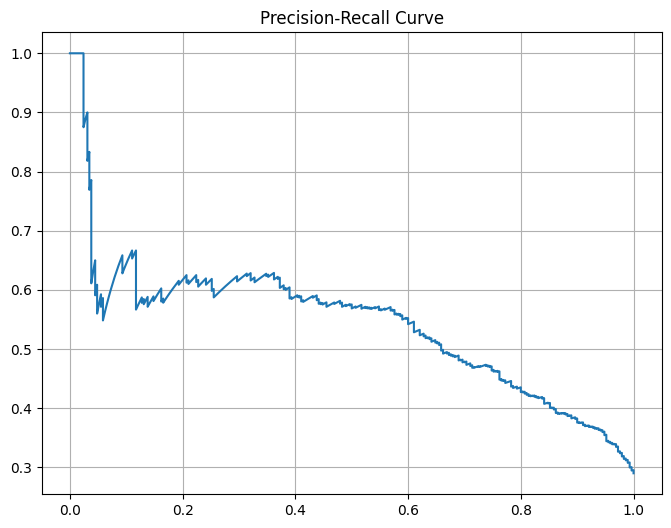

In [106]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    churn_prob
)
plt.figure(figsize=(8, 6))
plt.plot(
    recall,
    precision
)
plt.xlabel = "recall"
plt.ylabel = "precision"
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()

In [107]:
pr_auc = average_precision_score(y_test, churn_prob)
print("pr_auc=", pr_auc)

pr_auc= 0.5444579120744167


In [108]:
roc_auc = roc_auc_score(y_test, churn_prob)
print("roc_auc = ", roc_auc)

roc_auc =  0.7615735794074793


In [109]:
rf_model = RandomForestClassifier(
    n_estimators = 200,
    max_depth = None,
    min_samples_split = 2,
    random_state = 42,
    class_weight = "balanced"
)

In [110]:
rf_model.fit(
    X_train_processed,
    y_train
)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [111]:
rf_pred = rf_model.predict(X_test_processed)
print(rf_pred[:20])

[1 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0]


In [112]:
tree_counts = [50, 100, 200, 500]
results = []
for n in tree_counts:
    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
    rf.fit(X_train_processed, y_train)
    pred = rf.predict(X_test_processed)
    prob = rf.predict_proba(X_test_processed)[:, 1]
    results.append({
        "n_estimators": n,
        "F1": f1_score(y_test, pred),
        "ROC_AUC": roc_auc_score(y_test, prob),
        "Average_Precision": average_precision_score(
            y_test, prob
        )
    })
rf_results = pd.DataFrame(results)
print(rf_results.round(3))

   n_estimators     F1  ROC_AUC  Average_Precision
0            50  0.404    0.729              0.497
1           100  0.406    0.733              0.504
2           200  0.378    0.736              0.508
3           500  0.371    0.736              0.512


In [113]:
rf_500 = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)
rf_500.fit(X_train_processed, y_train)
rf_pred_500 = rf_500.predict(X_test_processed)
print("Precision:", precision_score(y_test, rf_pred_500))
print("Recall:", recall_score(y_test, rf_pred_500))
print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred_500))

Precision: 0.5510204081632653
Recall: 0.2793103448275862
Confusion matrix:
[[644  66]
 [209  81]]


In [114]:
rf_prob_500 = rf_500.predict_proba(
    X_test_processed
)[:, 1]
for threshold in [0.3, 0.4, 0.5]:
    pred = (rf_prob_500 >= threshold).astype(int)
    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision_score(y_test, pred):.3f} | "
        f"Recall: {recall_score(y_test, pred):.3f} | "
        f"F1: {f1_score(y_test, pred):.3f}"
    )

Threshold: 0.3 | Precision: 0.465 | Recall: 0.686 | F1: 0.554
Threshold: 0.4 | Precision: 0.517 | Recall: 0.510 | F1: 0.514
Threshold: 0.5 | Precision: 0.546 | Recall: 0.286 | F1: 0.376


In [115]:
thresholds = [
    0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50
]
rf_prob = rf.predict_proba(
    X_test_processed
)[:, 1]
results = []
for threshold in thresholds:
    pred = (rf_prob >= threshold).astype(int)
    results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred)
    })
threshold_results = pd.DataFrame(results)
print(threshold_results.round(3).to_string(index=False))

 threshold  accuracy  precision  recall    f1
      0.10     0.422      0.327   0.941 0.486
      0.15     0.525      0.368   0.893 0.522
      0.20     0.593      0.403   0.834 0.543
      0.25     0.642      0.434   0.772 0.556
      0.30     0.680      0.465   0.686 0.554
      0.35     0.709      0.499   0.617 0.552
      0.40     0.720      0.517   0.510 0.514
      0.45     0.726      0.537   0.397 0.456
      0.50     0.724      0.546   0.286 0.376


In [116]:
settings = [
    {"max_depth": 5,  "min_samples_leaf": 5},
    {"max_depth": 8,  "min_samples_leaf": 5},
    {"max_depth": 10, "min_samples_leaf": 5},
    {"max_depth": None, "min_samples_leaf": 5},
    {"max_depth": 8,  "min_samples_leaf": 10},
]
results = []
for setting in settings:
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=setting["max_depth"],
        min_samples_leaf=setting["min_samples_leaf"],
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_processed, y_train)
    probabilities = rf.predict_proba(
        X_test_processed
    )[:, 1]
    threshold = 0.30
    predictions = (probabilities >= threshold).astype(int)
    results.append({
        **setting,
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions)
    })
tuning_results = pd.DataFrame(results)
print(tuning_results.round(3).to_string(index=False))

 max_depth  min_samples_leaf  threshold  accuracy  precision  recall    f1
       5.0                 5        0.3     0.437      0.335   0.955 0.496
       8.0                 5        0.3     0.534      0.374   0.897 0.527
      10.0                 5        0.3     0.571      0.393   0.876 0.542
       NaN                 5        0.3     0.596      0.407   0.855 0.551
       8.0                10        0.3     0.514      0.364   0.900 0.518


In [117]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)
print("Model training:", X_fit.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)
print("\nChurn rates:")
print("Training:", round(y_fit.mean(), 3))
print("Validation:", round(y_val.mean(), 3))
print("Final test:", round(y_test.mean(), 3))

Model training: (3200, 12)
Validation: (800, 12)
Final test: (1000, 12)

Churn rates:
Training: 0.291
Validation: 0.29
Final test: 0.29


In [118]:
preprocessor_val = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_new),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)
X_fit_processed = preprocessor_val.fit_transform(X_fit)
X_val_processed = preprocessor_val.transform(X_val)
print("Training processed:", X_fit_processed.shape)
print("Validation processed:", X_val_processed.shape)

Training processed: (3200, 16)
Validation processed: (800, 16)


In [119]:
settings = [
    {"max_depth": 5, "min_samples_leaf": 5},
    {"max_depth": 8, "min_samples_leaf": 5},
    {"max_depth": 10, "min_samples_leaf": 5},
    {"max_depth": None, "min_samples_leaf": 5},
    {"max_depth": 8, "min_samples_leaf": 10}
]
thresholds = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
results = []
for setting in settings:
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=setting["max_depth"],
        min_samples_leaf=setting["min_samples_leaf"],
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_fit_processed, y_fit)
    probabilities = rf.predict_proba(
        X_val_processed
    )[:, 1]
    for threshold in thresholds:
        predictions = (
            probabilities >= threshold
        ).astype(int)
        results.append({
            "max_depth": setting["max_depth"],
            "min_samples_leaf": setting["min_samples_leaf"],
            "threshold": threshold,
            "accuracy": accuracy_score(y_val, predictions),
            "precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "recall": recall_score(y_val, predictions),
            "f1": f1_score(y_val, predictions, zero_division=0)
        })
validation_results = pd.DataFrame(results)
candidates = validation_results[
    validation_results["recall"] >= 0.65
].sort_values(
    ["precision", "f1"],
    ascending=False
)
print(candidates.round(3).to_string(index=False))

 max_depth  min_samples_leaf  threshold  accuracy  precision  recall    f1
       NaN                 5       0.40     0.652      0.442   0.750 0.556
      10.0                 5       0.40     0.645      0.437   0.780 0.560
       8.0                 5       0.40     0.631      0.428   0.806 0.559
       8.0                10       0.40     0.625      0.423   0.810 0.556
       NaN                 5       0.35     0.614      0.413   0.793 0.544
      10.0                 5       0.35     0.608      0.413   0.836 0.553
       5.0                 5       0.40     0.600      0.409   0.858 0.554
       8.0                10       0.35     0.588      0.404   0.884 0.554
       8.0                 5       0.35     0.580      0.396   0.858 0.542
       NaN                 5       0.30     0.576      0.395   0.871 0.544
      10.0                 5       0.30     0.569      0.393   0.892 0.545
       8.0                10       0.30     0.532      0.378   0.944 0.539
       8.0               

In [120]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])
final_model.fit(X_train, y_train)
final_probabilities = final_model.predict_proba(X_test)[:, 1]
chosen_threshold = 0.40
final_predictions = (
    final_probabilities >= chosen_threshold
).astype(int)
print("Threshold:", chosen_threshold)
print("Accuracy:", round(
    accuracy_score(y_test, final_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, final_predictions), 3
))
print("Recall:", round(
    recall_score(y_test, final_predictions), 3
))
print("F1:", round(
    f1_score(y_test, final_predictions), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, final_probabilities), 3
))
print("Average Precision:", round(
    average_precision_score(y_test, final_probabilities), 3
))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, final_predictions))
print("\nClassification report:")
print(classification_report(y_test, final_predictions))


Threshold: 0.4
Accuracy: 0.597
Precision: 0.407
Recall: 0.848
F1: 0.55
ROC-AUC: 0.759
Average Precision: 0.552

Confusion matrix:
[[351 359]
 [ 44 246]]

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.49      0.64       710
           1       0.41      0.85      0.55       290

    accuracy                           0.60      1000
   macro avg       0.65      0.67      0.59      1000
weighted avg       0.75      0.60      0.61      1000

